# Изучение клиентов фитнес-центра

# Автор: [Олег Булыгин](https://olegtalks.ru/)

<div style="background-color: #f5f5f5; border-left: 5px solid #3498db; padding: 10px; margin: 10px 0;">

## Обо мне

🐍 **Эксперт по Python и Data Science**. В 2020 году ушёл из найма, сейчас реализую собственные проекты, занимаюсь IT-образованием и консультированием.

👨‍💻 **Опыт в образовании**. В IT-образовании с 2017 года. За это время провел более 1500 лекций и вебинаров, обучил тысячи студентов, многие из которых сейчас работают в ведущих IT-компаниях. Создаю авторские курсы, консультирую крупные компании по вопросам Data Science и участвую в разработке образовательных программ для университетов и онлайн-школ.

🎯 Стремлюсь сделать обучение качественным и честным для всех, кто хочет развиваться в IT-сфере.

📱 Делюсь полезными материалами в своём [Telegram-канале об IT и AI](https://t.me/oleg_payload).
</div>

Задача классификации (classification) — задача, в которой мы пытаемся предсказать класс объекта на основе признаков в наборе данных. То есть задача сводится к предсказанию целевого признака, который является категориальным.

Когда классов, которые мы хотим предсказать, только два, классификация называется **бинарной**. Например, мы можем предсказать, болен ли пациент раком, является ли изображение человеческим лицом, является ли письмо спамом и т. д.

Когда классов, которые мы хотим предсказать, более двух, классификация называется **мультиклассовой**. Например, предсказание модели самолёта по радиолокационным снимкам, классификация животных на фотографиях, определение языка, на котором говорит пользователь, разделение писем на группы.



## Логистическая регрессия

Если взять в качестве разделяющей поверхности некоторую плоскость как на рисунке, то мы получаем модель логистической регрессии, которая тесно связана с рассмотренной нами ранее линейной регрессией.

Давайте для начала вспомним, как выглядит уравнение модели линейной регрессии в общем случае:

$$y = k_1x_1 + k_2x_2 + ... + k_nx_n + b$$

Что же делать с этой моделью, когда целевой признак  является категориальным? Например, является письмо спамом или обычным письмом?

Если у нас есть две категории, мы можем обозначить категории за y=1 (Спам) и y=0 (Не спам) и обучить линейную регрессию предсказывать 0 и 1.

Но результат будет очень плохим.



Вместо предсказания класса будем предсказывать **вероятность принадлежности** к этому классу.

Когда модель будет обучена на предсказание вероятности, мы зададим некоторый порог вероятности. Если предсказанная вероятность будет выше этого порога, мы определим объект к классу 1, а если ниже — к классу 0.

Например, стандартный порог равен 0.5. То есть если вероятность > 0.5, мы будем считать письмо спамом, а если <0.5 — обычным информативным письмом.

В итоге мы добьёмся того, что будем предсказывать не дискретный категориальный, а непрерывный числовой признак, который лежит в диапазоне [0, 1]. А это уже знакомая нам задача регрессии.

Но как научить модель предсказывать вероятности, ведь они должны лежать строго в диапазоне от 0 до 1, а предсказания линейной регрессии лежат в диапазоне от -бесконечности до бесконечности?




В основе логистической регрессии лежит логистическая функция (logistic function)  — отсюда и название модели. Однако более распространённое название этой функции — сигмόида (sigmoid). Записывается она следующим образом:

$$\sigma(x) = \frac{1}{1 + e^{-x}}$$

А вот ее график:

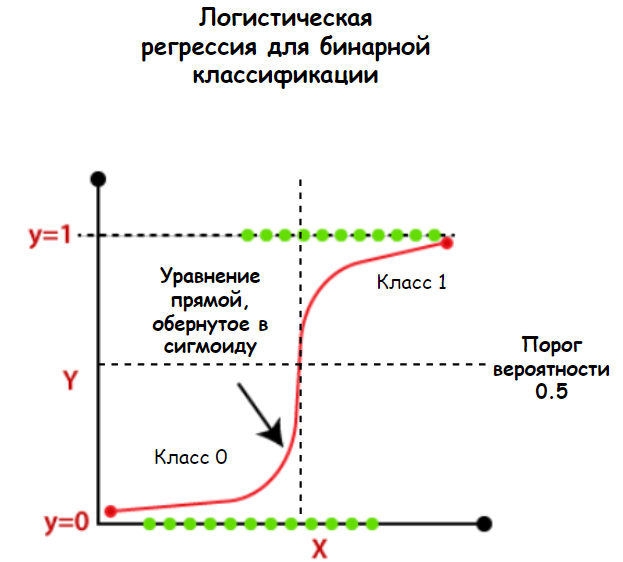

Для случая зависимости целевого признака от трёх факторов, и , например от баллов за два экзамена и рейтинга университета, из которого выпустился абитуриент.  Разделяющая плоскость будет выглядеть следующим образом:



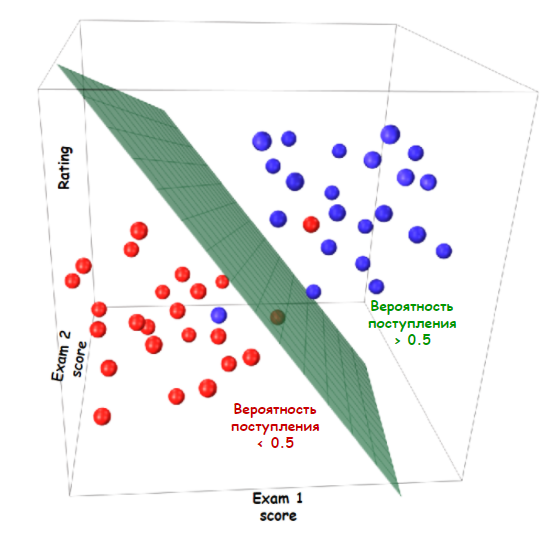

Для сети пользователей фитнес-центров необходимо:
- спрогнозировать вероятность оттока клиента;
- сформировать типичные портреты пользователей;
- выявить основные признаки, наиболее сильно влияющие на отток.

### Описание данных

- 'Churn' — факт оттока в текущем месяце;
- 'gender' — пол
- 'Near_Location' — проживание или работа в районе, где находится фитнес-центр
- 'Partner' — сотрудник компании-партнёра клуба
- 'Promo_friends' — факт первоначальной записи в рамках акции «приведи друга»
- 'Phone' — наличие контактного телефона
- 'Age' — возраст
- 'Lifetime' — время с момента первого обращения в фитнес-центр (в месяцах)
- 'Contract_period' — длительность текущего действующего абонемента (месяц, 6 месяцев, год)
- 'Month_to_end_contract' — срок до окончания текущего действующего абонемента (в месяцах)
- 'Group_visits' — факт посещения групповых занятий
- 'Avg_class_frequency_total' — средняя частота посещений в неделю за все время с начала действия абонемента
- 'Avg_class_frequency_current_month' — средняя частота посещений в неделю за предыдущий месяц
- 'Avg_additional_charges_total' — средняя выручка от других услуг фитнес-центра: кафе, спорт-товары и тд

## Загрузка и подготовка данных

In [ ]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
!pip install phik -q
import phik
from phik.report import plot_correlation_matrix
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/obulygin/content/main/gym_churn/gym_churn.csv')

Проведем базовые проверки: посмотрим на типы данных, наличие пропусков и дубликатов.

In [ ]:
# Общая информация
print("\nОбщая информация о DataFrame:")
df.info()

display(df)

# Проверка на полные дубликаты
duplicates_count = df.duplicated().sum()
print(f"\nКоличество полных дубликатов: {duplicates_count}")
if duplicates_count == 0:
    print("Полных дубликатов нет.")

# Проверка на пропуски (хотя info() уже показывает, но для наглядности)
missing_values = df.isnull().sum().sum()
print(f"\nОбщее количество пропущенных значений: {missing_values}")
if missing_values == 0:
    print("Пропущенных значений нет.")


Общая информация о DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   int64  
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_frequency_total

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.227470,5,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,13,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,2,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,2,3,1.113884,1.120078,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,1,1,1,0,1,12,0,33,2.406023,12,8,2.284497,2.349070,0
3996,0,1,0,0,1,1,1,29,68.883764,2,1,1.277168,0.292859,1
3997,1,1,1,1,1,12,0,28,78.250542,11,2,2.786146,2.831439,0
3998,0,1,1,1,1,6,0,32,61.912657,5,3,1.630108,1.596237,0



Количество полных дубликатов: 0
Полных дубликатов нет.

Общее количество пропущенных значений: 0
Пропущенных значений нет.


Для удобства работы и избежания ошибок из-за регистра приведем все названия столбцов к нижнему регистру.


In [ ]:
# приведем названия столбцов к нижнему регистру
df.columns = df.columns.str.lower()

## EDA

### Описательные статистики

Первым делом посмотрим на наш целевой признак — `churn`. Сколько клиентов ушло, а сколько осталось?

Доля оставшихся клиентов (churn=0): 73.47%
Доля ушедших клиентов (churn=1): 26.52%


[Text(0, 0, '2939'), Text(0, 0, '1061')]

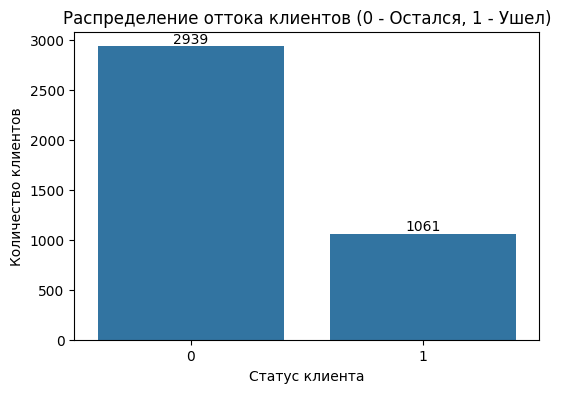

In [ ]:
# Рассчитываем и выводим долю каждого класса
churn_rate = df['churn'].value_counts(normalize=True) * 100
print(f"Доля оставшихся клиентов (churn=0): {churn_rate[0]:.2f}%")
print(f"Доля ушедших клиентов (churn=1): {churn_rate[1]:.2f}%")

# Визуализируем распределение целевой переменной
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='churn', data=df)
plt.title('Распределение оттока клиентов (0 - Остался, 1 - Ушел)')
plt.xlabel('Статус клиента')
plt.ylabel('Количество клиентов')
plt.bar_label(ax.containers[0])

У нас 27% клиентов ушло в отток в текущем месяце, 73% осталось.

**Несбалансированный** набор данных (unbalanced dataset) — это выборка, в которой количества объектов каждого из классов значительно отличаются.

Очевидно, что такая проблема в первую очередь актуальна для задач классификации.

Зачем обращать внимание на несбалансированные данные? Вам может потребоваться применить определенный метод выборки, если у вас есть задача классификации с несбалансированным набором данных.

Рассмотрим следующий пример модели, обнаруживающей мошенничество. Случаи мошенничества происходят один раз на 200 транзакций в этом наборе данных, поэтому в истинном распределении около 0,5% данных являются положительными.

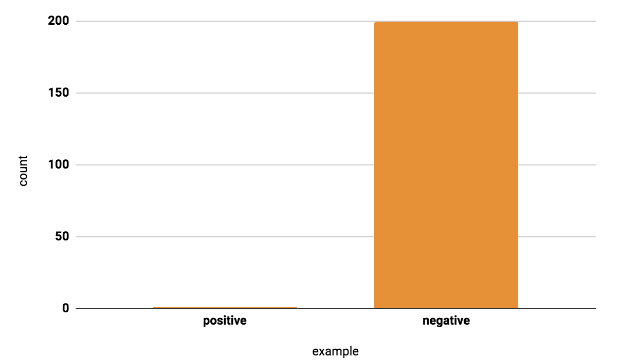

Почему это может быть проблематично?
При разбиении несбалансированной выборки на тренировочную/валидационную/тестовую увеличивается шанс попадания в одну из них объектов только одного класса, из-за чего оценка качества модели может быть необъективной.

*Accuracy очень плохой выбор для оценки моделей при дисбалансе классов.*

Поэтому используются метрики, которые концентрируются на каждом из классов отдельно, — это precision, recall и F1-score.

Также были разработаны специальные метрики, основанные на accuracy: это функционал Каппа Коэна (Cohen’s Kappa) и balanced accuracy. Подробнее о них вы можете прочитать [здесь](https://alexanderdyakonov.wordpress.com/2019/05/31/%D1%84%D1%83%D0%BD%D0%BA%D1%86%D0%B8%D0%BE%D0%BD%D0%B0%D0%BB%D1%8B-%D0%BA%D0%B0%D1%87%D0%B5%D1%81%D1%82%D0%B2%D0%B0-%D0%B2-%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B5-%D0%B1%D0%B8%D0%BD%D0%B0%D1%80%D0%BD/).

А некоторые стандартные методы ML, такие как дерево решений и логистическая регрессия, имеют тенденцию игнорировать класс меньшинства.

### Оценка средних значений признаков по группам ушедших и оставшихся

Посмотрим на средние значения признаков в двух группах — тех, кто ушел в отток и тех, кто остался.

In [ ]:
print("\nСредние значения признаков в разрезе оттока:")
churn_comparison = df.groupby('churn').agg('mean').round(2).T # Транспонируем для сравнения столбцов 0 и 1
churn_comparison


Средние значения признаков в разрезе оттока:


churn,0,1
gender,0.51,0.51
near_location,0.87,0.77
partner,0.53,0.36
promo_friends,0.35,0.18
phone,0.90,0.90
contract_period,5.75,1.73
group_visits,0.46,0.27
age,29.98,26.99
avg_additional_charges_total,158.45,115.08
month_to_end_contract,5.89,2.58


Уже на уровне средних видны явные различия между группами. Кажется, лояльные клиенты (оставшиеся) старше, имеют более длительные контракты, дольше ходят в клуб, посещают чаще (в т.ч. групповые занятия) и больше тратят.

Давайте визуализируем эти различия, чтобы лучше понять распределения. Разделим признаки на категориальные (включая бинарные) и числовые.


In [ ]:
# Определяем типы признаков (исключая целевую переменную)
all_features = df.drop('churn', axis=1).columns.tolist()
categorical_features = []
numerical_features = []

for col in all_features:
    if df[col].nunique() <= 5: # Считаем признаки с 5 или менее уникальными значениями категориальными/бинарными
        categorical_features.append(col)
    else:
        numerical_features.append(col)


print(f"\nКатегориальные признаки: {categorical_features}")
print(f"Числовые признаки: {numerical_features}")




Категориальные признаки: ['gender', 'near_location', 'partner', 'promo_friends', 'phone', 'contract_period', 'group_visits']
Числовые признаки: ['age', 'avg_additional_charges_total', 'month_to_end_contract', 'lifetime', 'avg_class_frequency_total', 'avg_class_frequency_current_month']



Визуализация категориальных признаков (с долями оттока):


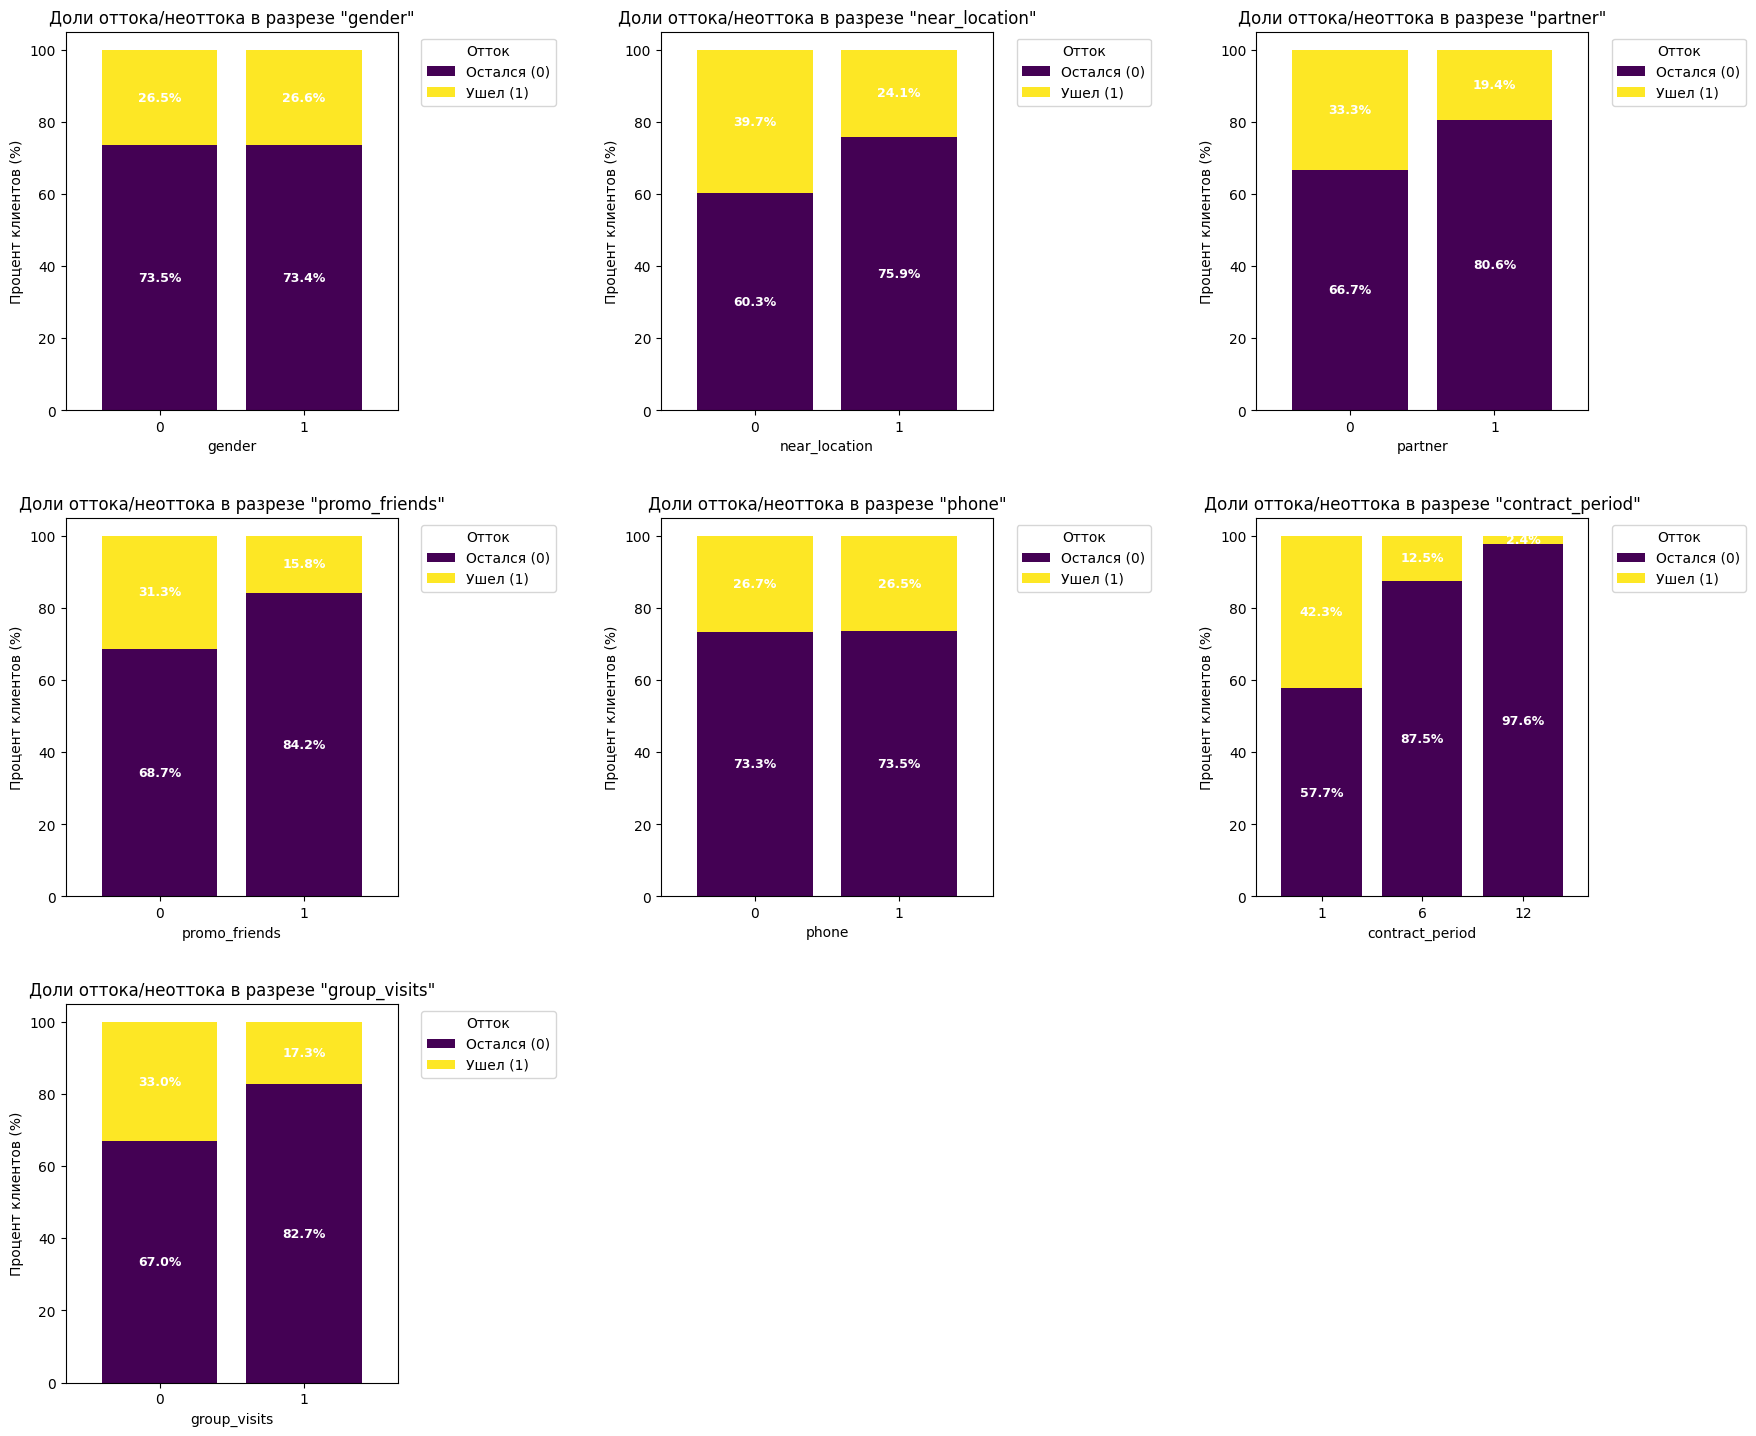

In [ ]:
# --- Визуализация Категориальных Признаков с Долями ---
print("\nВизуализация категориальных признаков (с долями оттока):")
n_cat = len(categorical_features)
n_cols_cat = 3
n_rows_cat = math.ceil(n_cat / n_cols_cat)

plt.figure(figsize=(n_cols_cat * 6, n_rows_cat * 5))
for i, col in enumerate(categorical_features):
    plt.subplot(n_rows_cat, n_cols_cat, i + 1)

    # 1. Группируем и считаем количество для каждой комбинации признака и оттока
    counts = df.groupby([col, 'churn']).size().unstack(fill_value=0)
    # 2. Считаем общие суммы для каждой категории признака
    totals = counts.sum(axis=1)
    # 3. Считаем процентное соотношение
    percentages = counts.apply(lambda x: x / totals * 100)

    # 4. Строим stacked barplot
    ax = percentages.plot(kind='bar', stacked=True, ax=plt.gca(), colormap='viridis', width=0.8)

    plt.title(f'Доли оттока/неоттока в разрезе "{col}"')
    plt.xlabel(col)
    plt.ylabel('Процент клиентов (%)')
    plt.xticks(rotation=0) # Убираем поворот меток оси X
    plt.legend(title='Отток', labels=['Остался (0)', 'Ушел (1)'], bbox_to_anchor=(1.05, 1), loc='upper left') # Легенду чуть в сторону

    # 5. Добавляем метки процентов на бары (немного сложнее для stacked)
    for container in ax.containers:
        # Форматируем метки, показываем только > 1% для читаемости
        labels = [f'{v:.1f}%' if v > 1 else '' for v in container.datavalues]
        ax.bar_label(container, labels=labels, label_type='center', color='white', fontsize=9, fontweight='bold')

plt.tight_layout(pad=3.0)
plt.subplots_adjust(right=0.9) # Даем место для легенды
plt.show()


Визуализация числовых признаков:


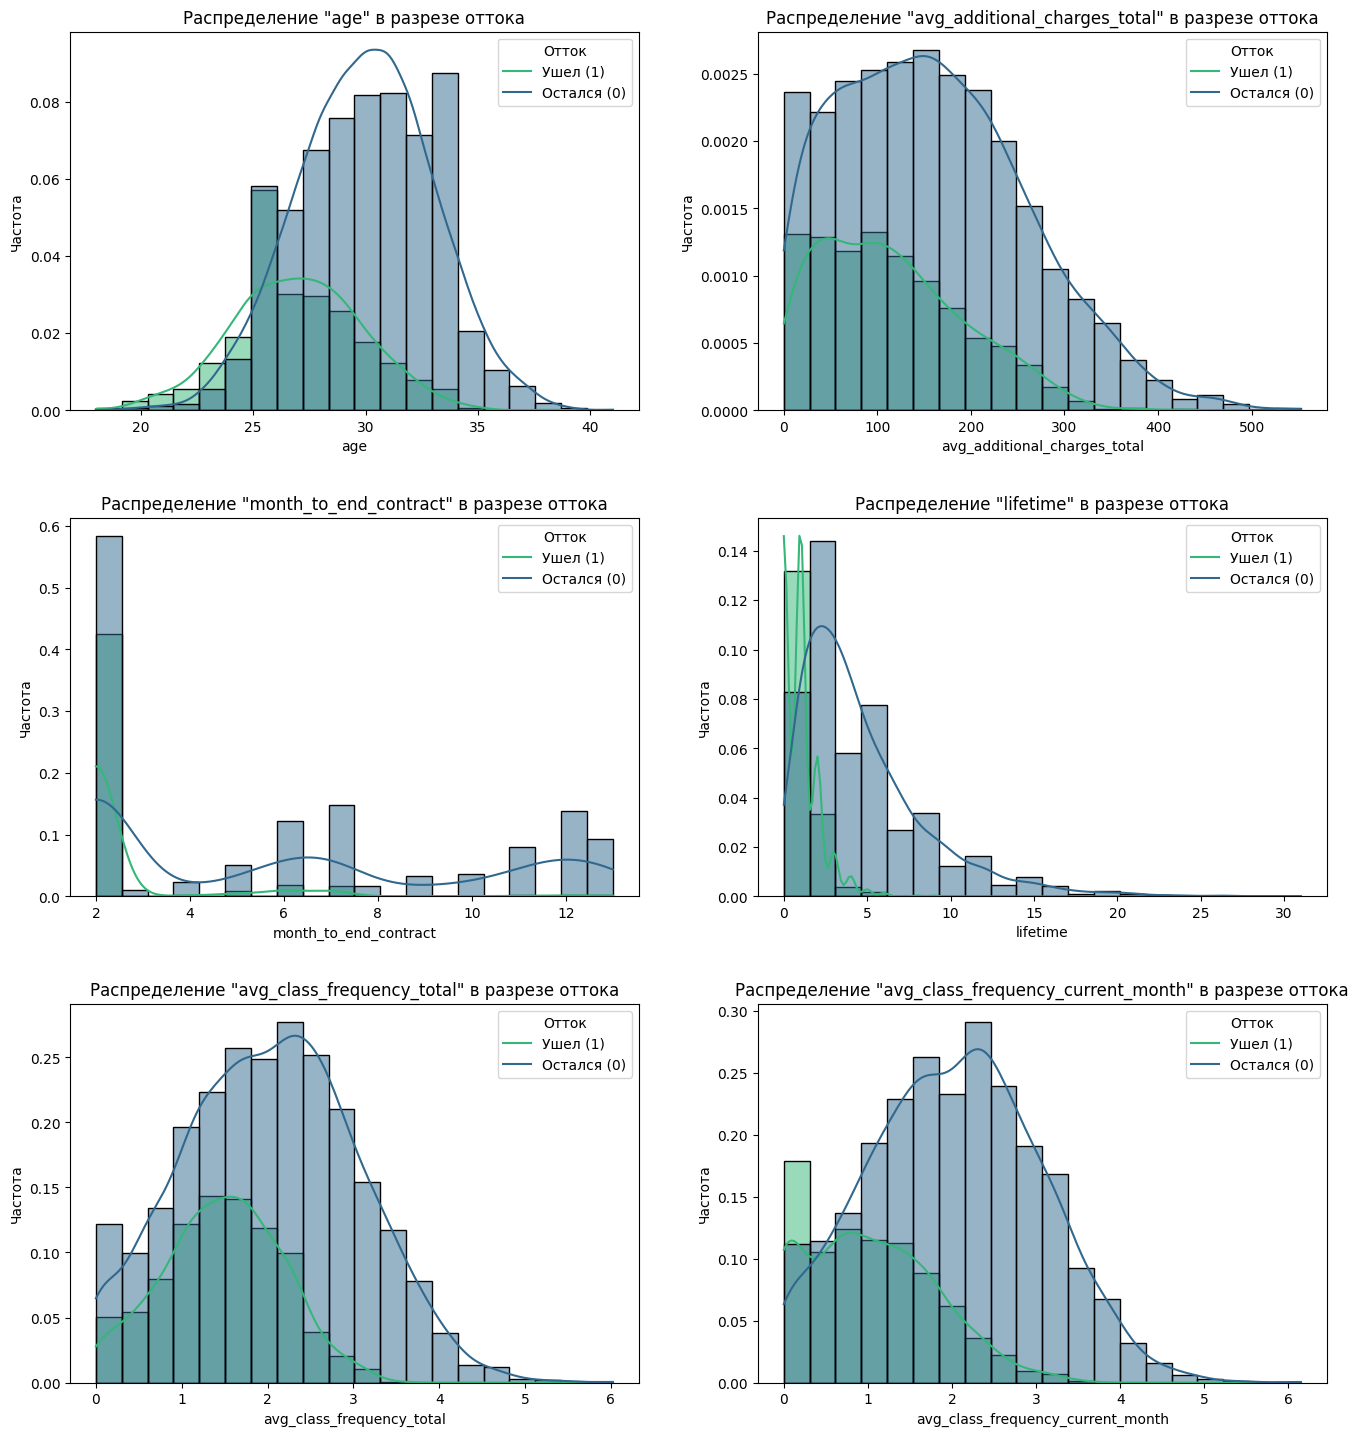

In [ ]:
# --- Визуализация Числовых Признаков ---
print("\nВизуализация числовых признаков:")
n_num = len(numerical_features)
n_cols_num = 2
n_rows_num = math.ceil(n_num / n_cols_num)

plt.figure(figsize=(n_cols_num * 7, n_rows_num * 5))
for i, col in enumerate(numerical_features):
    plt.subplot(n_rows_num, n_cols_num, i + 1)
    # Используем histplot с hue для сравнения распределений
    sns.histplot(data=df, x=col, hue='churn', kde=True, palette='viridis', bins=20, stat='density')
    plt.title(f'Распределение "{col}" в разрезе оттока')
    plt.xlabel(col)
    plt.ylabel('Частота')
    plt.legend(title='Отток', labels=['Ушел (1)', 'Остался (0)']) # Порядок в legend может зависеть от отрисовки
plt.tight_layout(pad=3.0)
plt.show()


### Выявление мультиколлинеарности

Теперь посмотрим на взаимосвязи между всеми признаками, включая целевую переменную `churn`. Используем коэффициент корреляции Phik (φk), который хорошо работает с разными типами данных (числовыми, категориальными) и улавливает нелинейные зависимости.



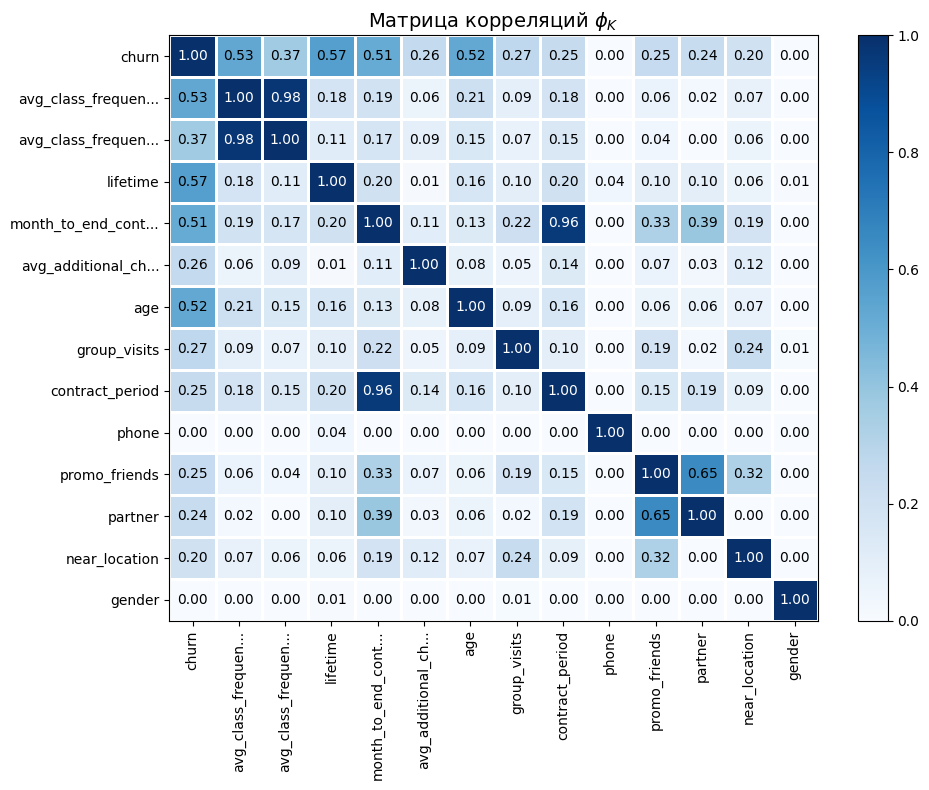

In [ ]:
phik_overview = df.phik_matrix(interval_cols=numerical_features)

# Визуализируем матрицу Phik
# Увеличим размер для лучшей читаемости
plot_correlation_matrix(phik_overview.values,
                        x_labels=phik_overview.columns,
                        y_labels=phik_overview.index,
                        vmin=0, vmax=1, # Phik >= 0
                        color_map="Blues", # Выберем другую палитру
                        title=r"Матрица корреляций $\phi_K$",
                        fontsize_factor=1.0, # Немного уменьшим шрифт, если много признаков
                        figsize=(10, 8))
plt.tight_layout()
plt.show()


In [ ]:

# Выведем корреляции всех признаков с 'churn' для удобства
print("\nКорреляция Phik признаков с оттоком ('churn'):")
# Сортируем по убыванию модуля корреляции, исключая сам churn
print(phik_overview['churn'].sort_values(ascending=False).drop('churn'))


Корреляция Phik признаков с оттоком ('churn'):
lifetime                             0.568174
avg_class_frequency_current_month    0.528380
age                                  0.524050
month_to_end_contract                0.512427
avg_class_frequency_total            0.370023
group_visits                         0.270011
avg_additional_charges_total         0.257619
promo_friends                        0.250009
contract_period                      0.247718
partner                              0.243579
near_location                        0.197164
phone                                0.000000
gender                               0.000000
Name: churn, dtype: float64


Очевидно наличие мультиколлинеарности в матрице наших признаков, т.к. мы имеем 2 пары очень высоко-корреллирующих между собой признаков: это параметры `общий срок абонемента`  и `срок до конца абонемента` , имеющие коэффициент корреляции 0.96, а также параметры `общая частота посещений` и `частота посещений в последний месяц`.  На интуитивном уровне также понятна их высокая взаимосвязь.

Некоторые прогнозные модели (в частности, модель логистической регресии, которую мы далее планируем использовать в исследовании) очень чувствительны к мультиколлинеарности. Потому нам следует избавиться от дублирующих признаков.

Среди первый двух признаков более показательным будем считать общий срок абонемента, поскольку второй признак (срок до конца абонемента) в большей степени зависит от временной точки, когда собирались данные. Общий же срок абонемента показывает, на сколько серъёзно клиент настроен в момент его покупки. Так что оставим `общий срок абонемента` и удалим `срок до конца абонемента`.

Аналогично со второй парой признаков: скорее, показательней является частота посещений на длительном промежутке, нежели чем в послений месяц, поскольку в последний месяц может попасть отпуск клиента, и это спровоцирует на ошибочное установдение признака оттока. Оставляем `общая частота посещений` (удаляем `частота посещений в последний месяц`).

In [ ]:
df = df.drop(['contract_period', 'avg_class_frequency_total', 'phone', 'gender'], axis = 1)

## 2. Построение модели прогнозирования оттока пользователей<a id='binary_model'></a>

### Разделение и стандартизация выборок

Построим модель бинарной классификации пользователей, где целевой признак — факт оттока пользователя в следующем месяце.

Для того чтобы снизить влияние дисбаланса классов при разбиении выборки, в наборе данных используется специальный тип разбиения, который называется стратифицированным (stratified). Данное разбиение предполагает, что наблюдения, принадлежащие каждому из классов, гарантированно попадут в каждый из наборов данных в одинаковой пропорции.

In [ ]:
# разделим наши данные на признаки (матрица X) и целевую переменную (y)
from sklearn.model_selection import train_test_split

X = df.drop('churn', axis = 1)
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, stratify=y)

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Строим модель

Используем алгоритм логистической регрессии, обучим модель на обучающей выборке, сделаем прогноз на тестовой выборке и посчитаем метрики.

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42)

# обучим модель лог.регрессии
lr_model.fit(X_train, y_train)

# воспользуемся уже обученной моделью, чтобы сделать прогнозы
lr_predictions = lr_model.predict(X_test)



In [ ]:
print(classification_report(y_test, lr_predictions))

              precision    recall  f1-score   support

           0       0.93      0.94      0.93       735
           1       0.83      0.80      0.81       265

    accuracy                           0.90      1000
   macro avg       0.88      0.87      0.87      1000
weighted avg       0.90      0.90      0.90      1000



Метрика `accuracy` является одной из метрик алгоритмов бинарной классификации и означает долю верно угаданных ответов из всех прогнозов. Чем ближе значение `accuracy` к 100%, тем лучше. В нашем случае она составляет 0.90 для алгоритма логистической регрессии. Однако, данная метрика хорошо работает только в случае, если классы сбалансированы, то есть когда объектов каждого класса примерно поровну, 50% : 50%. Но мы ранее посчитали, что в нашей задаче классы имеют соотношение 27% : 73%, то есть баланс классов не соблюден. Так как классы не сбалансированны, то эта метрика скорей показывает не то, на сколько хорошо модель предсказывает положительные исходы (единицы, или отток в нашем случае), а то, насколько хорошо она определяет превалирующий класс.

Метрика `precision` говорит, какая доля прогнозов относительно "1" класса верна. То есть смотрим долю правильных ответов только среди целевого класса (класс "оттока").  В бизнесе метрика precision нужна, если каждое срабатывание  модели ( факт отнесения к классу "1" стоит ресурсов, а бизнес не хочет, чтобы модель часто «срабатывала попусту». `Precision` составляет 0.83.

Метрика `recall` нацелена на минимизацию противоположных рисков:  показывает, сколько реальных объектов "1" класса мы смогли обнаружить с помощью модели.


Text(50.722222222222214, 0.5, 'Факт')

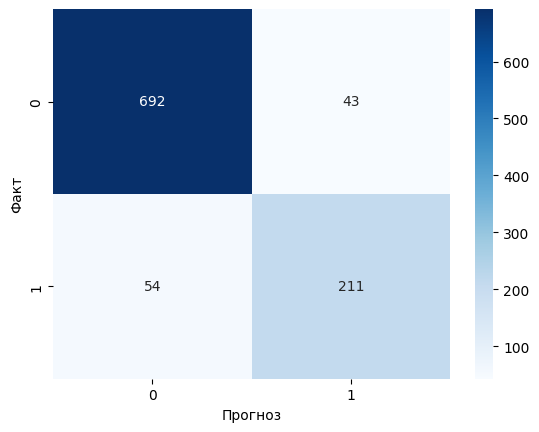

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, lr_predictions)
sns.heatmap(cm, annot=True, fmt='', cmap='Blues')
plt.xlabel('Прогноз')
plt.ylabel('Факт')

### Смещение порога

Представим ситуацию, что онкодиагностика в клинике довольно дорогая. Но при этом нам важно выявить злокачественные опухоли у как можно большего числа людей (у которых они есть). То есть нам важен и precision, и recall.

Можем ли мы как-то улучшить метрики?

Давайте будем изменять порог принятия решений. По умолчанию в sklearn порог вероятности для моделей классификации составляет 0.5. То есть если вероятность наличия злокачественной опухоли у пациента выше 0.5, то модель относит его к к классу 1, а если меньше 0.5 — то к 0.


Но как будут меняться значения метрик recall, precision и F1, если мы попробуем изменить порог вероятности, например на 0.4, 0.3 или 0.6? Давайте проследим за этим.

*Геометрически регулировка порога вероятности для логистической регрессии означает движение разделяющей плоскости.*

Сделаем предсказание вероятности наличия злокачественной опухоли моделью со всеми признаками для каждого пациента из нашей выборки. Затем создадим несколько различных порогов вероятности в диапазоне от 0.1 до 1 с шагом 0.05. В цикле будем определять класс пациента при различных порогах вероятности. В конце рассчитаем метрики.




In [ ]:
from sklearn.metrics import recall_score, precision_score, f1_score

# Нас интересует только вероятность класса (второй столбец)
y_proba_pred = lr_model.predict_proba(X_test)[:, 1]

# Для удобства завернём numpy-массив в Pandas Series
y_proba_pred = pd.Series(y_proba_pred)

y_proba_pred


,0
0,0.757210
1,0.037141
2,0.000555
3,0.383348
4,0.000106
...,...
995,0.049367
996,0.902166
997,0.001127
998,0.955387


In [ ]:
# Создадим списки, в которых будем хранить значения метрик
recall_scores = []
precision_scores = []
f1_scores = []

# Сгенерируем набор вероятностных порогов в диапазоне от 0.1 до 1
thresholds = np.arange(0.1, 1, 0.05)

# В цикле будем перебирать сгенерированные пороги
for threshold in thresholds:
    # Пациентов, для которых вероятность наличия злокачественной опухоли > threshold, относим к классу 1
    # В противном случае — к классу 0
    y_pred = y_proba_pred.apply(lambda x: 1 if x>threshold else 0)
    #Считаем метрики и добавляем их в списки
    recall_scores.append(recall_score(y_test, y_pred))
    precision_scores.append(precision_score(y_test, y_pred))
    f1_scores.append(f1_score(y_test, y_pred))

Теперь у нас есть три списка (recall_scores, precision_scores и f1_scores), в которых хранятся значения метрик при различных значениях порога вероятности p.

Давайте построим графики зависимости метрик от порога вероятности:

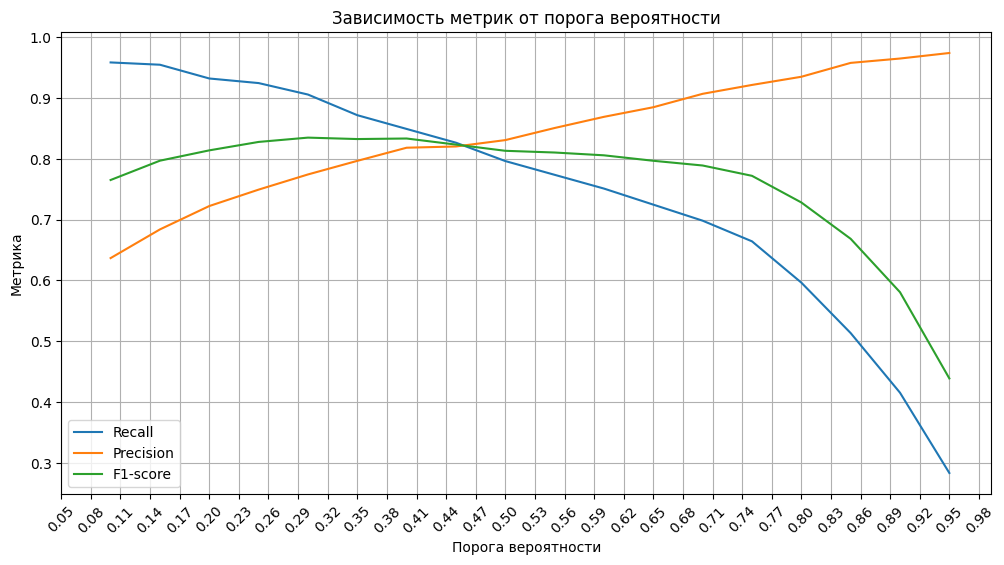

In [ ]:
# Строим линейный график зависимости recall от threshold
plt.figure(figsize=(12, 6))
plt.plot(thresholds, recall_scores, label='Recall')
# Строим линейный график зависимости precision от threshold
plt.plot(thresholds, precision_scores, label='Precision')
# Строим линейный график зависимости F1 от threshold
plt.plot(thresholds, f1_scores, label='F1-score')

plt.title('Зависимость метрик от порога вероятности')
plt.xlabel('Порога вероятности')
plt.ylabel('Метрика')
plt.xticks(thresholds)
plt.xticks(np.arange(0.05, 1, 0.03), rotation=45)
plt.grid(True)
plt.legend()

С увеличением вероятностного порога повышается precision и падает recall.

При этом значение F1-меры сначала повышается, а затем падает.

Интересным является значение около 0.45, где происходит пересечение всех трёх графиков. Это точка равенства precision и recall и, как следует из формулы, равенства F1-меры.

Перед нами стоит выбор, какя метрика для нас важнее (или их равенство).



In [ ]:
#Задаём оптимальный порог вероятностей
threshold_opt = 0.45
#Пациентов, для которых вероятность наличия злокачественной опухоли > 0.52, относим к классу 1
#В противном случае — к классу 0
y_pred_opt = y_proba_pred.apply(lambda x: 1 if x > threshold_opt else 0)
#Считаем метрики
print(classification_report(y_test, y_pred_opt))

              precision    recall  f1-score   support

           0       0.94      0.93      0.94       735
           1       0.82      0.83      0.82       265

    accuracy                           0.91      1000
   macro avg       0.88      0.88      0.88      1000
weighted avg       0.91      0.91      0.91      1000



<Axes: >

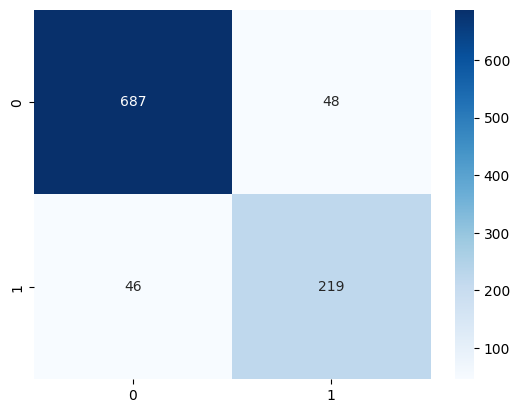

In [ ]:
confusion_matrix3 = confusion_matrix(y_test, y_pred_opt)
sns.heatmap(confusion_matrix3, annot=True, fmt='d', cmap='Blues')


#### Борьба с дисбалансом классов

Существует несколько способов уменьшить влияние дисбаланса на обучение модели:

- **Взвешивание объектов**. В функцию ошибки добавляется штраф, прямо пропорциональный количеству объектов каждого класса. Это очень похоже на регуляризацию.

- **Сэмплирование** (sampling) — перебалансировка выборки искусственным путём:
upsampling — искусственное увеличение количества объектов миноритарного класса;
downsampling — сокращение количества объектов мажоритарного класса.

#### Взвешиваение классов

Большинство моделей, реализованных в sklearn, имеют параметр **class_weight** — веса классов. Чтобы сбалансировать важность классов, обычно берут веса объектов класса-большинства (мажоритарного класса) равным 1, а веса объектов малочисленного (миноритарного) класса вычисляются по следующей формуле:
$$
\text{weight}_i = \frac{\text{n_samples}}{\text{n_classes} \times \text{n_samples}_i}
$$

где:
- $ \text{n_samples} $: общее количество объектов в данных,
- $ \text{n_classes} $: количество уникальных классов,
- $ \text{n_samples}_i $: количество объектов в классе $ i $.


Для того чтобы задать веса классам по приведённым выше формулам, достаточно в инициализаторе модели выставить параметр `class_weight='balanced'`.



              precision    recall  f1-score   support

           0       0.97      0.90      0.93       735
           1       0.77      0.92      0.84       265

    accuracy                           0.90      1000
   macro avg       0.87      0.91      0.88      1000
weighted avg       0.91      0.90      0.91      1000



Text(50.722222222222214, 0.5, 'Факт')

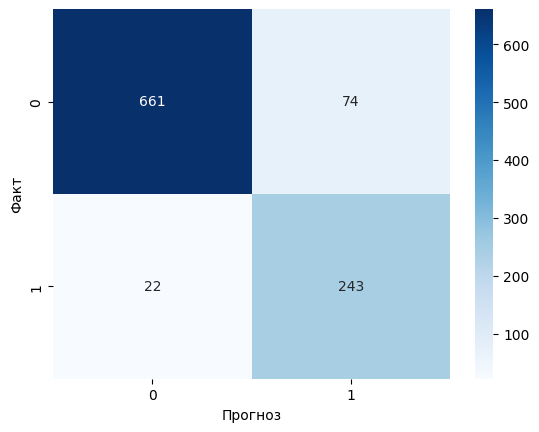

In [ ]:
lr_model = LogisticRegression(random_state=42, class_weight='balanced')

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print(classification_report(y_test, lr_predictions))

cm = confusion_matrix(y_test, lr_predictions)
sns.heatmap(cm, annot=True, fmt='', cmap='Blues')
plt.xlabel('Прогноз')
plt.ylabel('Факт')

##### Сэмплирование

Идея данного подхода: если у нас мало наблюдений миноритарного класса, следует искусственно увеличить их количество. А ещё уменьшить количество мажоритарного. Начнём с этого способа.



###### Downsampling

Простейший способ сокращения выборки мажоритарных классов - случайное удаление записей из этой категории.

Для этого будем использовать класс RandomUnderSampler из библиотеки imblearn.

In [ ]:
from imblearn.under_sampling import RandomUnderSampler


# Инициализируем RandomUnderSampler
rus = RandomUnderSampler(random_state=42)

# Применяем downsampling
X_train_down, y_train_down = rus.fit_resample(X_train, y_train)

print(f'Размерность тренировочной выборки до сэмплирования: {X_train.shape}')
print(f'Баланс классов до сэмплирования:\n{y_train.value_counts()}')
print('-'*40)
print(f'Размерность тренировочной выборки после сэмплирования: {X_train_down.shape}')
print(f'Баланс классов после сэмплирования:\n{y_train_down.value_counts()}')

Размерность тренировочной выборки до сэмплирования: (3000, 9)
Баланс классов до сэмплирования:
churn
0    2204
1     796
Name: count, dtype: int64
----------------------------------------
Размерность тренировочной выборки после сэмплирования: (1592, 9)
Баланс классов после сэмплирования:
churn
0    796
1    796
Name: count, dtype: int64


              precision    recall  f1-score   support

           0       0.97      0.89      0.93       735
           1       0.76      0.92      0.83       265

    accuracy                           0.90      1000
   macro avg       0.86      0.91      0.88      1000
weighted avg       0.91      0.90      0.90      1000



Text(50.722222222222214, 0.5, 'Факт')

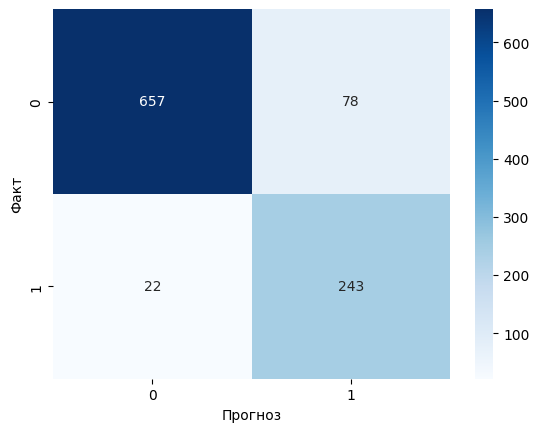

In [ ]:
lr_model = LogisticRegression(random_state=42)

lr_model.fit(X_train_down, y_train_down)

lr_predictions = lr_model.predict(X_test)

print(classification_report(y_test, lr_predictions))

cm = confusion_matrix(y_test, lr_predictions)
sns.heatmap(cm, annot=True, fmt='', cmap='Blues')
plt.xlabel('Прогноз')
plt.ylabel('Факт')

###### Upsampling

Заключается в том, чтобы случайные образом скопировать объекты из миноритарного класса так, чтобы их по количество приравнять к мажоритарному классу.

Тут мы инициализируем `RandomOverSampler` и выполняем upsampling с помощью метода `fit_resample`. Этот метод возвращает новые массивы, в которых классы сбалансированы.

In [ ]:
from imblearn.over_sampling import RandomOverSampler

# Инициализируем RandomOverSampler
ros = RandomOverSampler(random_state=42)

# Выполняем upsampling
X_train_up, y_train_up = ros.fit_resample(X_train, y_train)

print(f'Размерность тренировочной выборки до сэмплирования: {X_train.shape}')
print(f'Баланс классов до сэмплирования:\n{y_train.value_counts()}')
print('-'*40)
print(f'Размерность тренировочной выборки после сэмплирования: {y_train_up.shape}')
print(f'Баланс классов после сэмплирования:\n{y_train_up.value_counts()}')

Размерность тренировочной выборки до сэмплирования: (3000, 9)
Баланс классов до сэмплирования:
churn
0    2204
1     796
Name: count, dtype: int64
----------------------------------------
Размерность тренировочной выборки после сэмплирования: (4408,)
Баланс классов после сэмплирования:
churn
1    2204
0    2204
Name: count, dtype: int64


              precision    recall  f1-score   support

           0       0.96      0.90      0.93       735
           1       0.76      0.91      0.83       265

    accuracy                           0.90      1000
   macro avg       0.86      0.90      0.88      1000
weighted avg       0.91      0.90      0.90      1000



Text(50.722222222222214, 0.5, 'Факт')

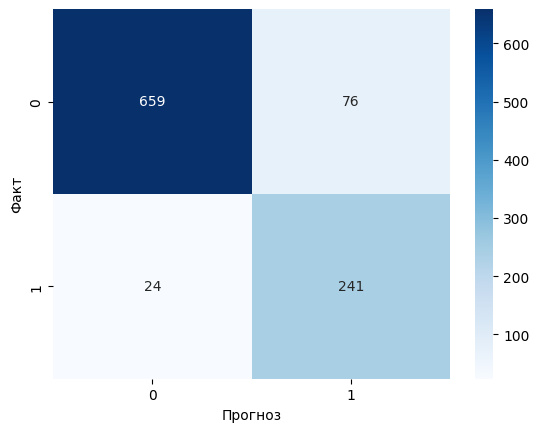

In [ ]:
lr_model = LogisticRegression(random_state=42)

lr_model.fit(X_train_up, y_train_up)

lr_predictions = lr_model.predict(X_test)

print(classification_report(y_test, lr_predictions))

cm = confusion_matrix(y_test, lr_predictions)
sns.heatmap(cm, annot=True, fmt='', cmap='Blues')
plt.xlabel('Прогноз')
plt.ylabel('Факт')

Приведенные выше алгоритмы могут улучшать качество, но есть и специальные алгоритмы генерации искусственных данных, например SMOTE. Можете почитать [здесь](https://alexanderdyakonov.wordpress.com/2021/05/27/imbalance/) и [здесь](https://loginom.ru/blog/imbalance-class)


Какой из методов сработает лучше, заранее сказать нельзя, нужно экспериментировать :)

## Итоги: преимущества и недостатки логистической регрессии

Преимущества:  
- Простой, интерпретируемый, но в то же время эффективный алгоритм. Благодаря этому он очень популярен в ML.  
- Поиск параметров линейный или квадратичный (в зависимости от метода оптимизации), то есть ресурсозатратность алгоритма очень низкая.  
- Не требует подбора внешних параметров (гиперпараметров), так как практически не зависит от них.

Недостатки:   
- Алгоритм работает хорошо, только когда классы линейно разделимы, что в реальных задачах бывает очень редко. Поэтому обычно данная модель используется в качестве baseline.
- Недостаток с линейной разделимостью классов можно побороть с помощью введения полиномиальных признаков, тем самым снизив смещение модели. Тогда логистическая регрессия вместо разделяющей плоскости будет означать выгнутую разделяющую поверхность сложной структуры.
Однако мы знаем, что с этим трюком стоит быть аккуратным, так как можно получить переобученную модель. Поэтому в комбинации с полиномиальными признаками стоит подобрать наилучший параметр регуляризации.


